<a href="https://colab.research.google.com/github/sergiomorapardo/StochasticAITechniquesClass/blob/main/Notebooks/L14_HackathonFraming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook: Hackatón — Encuadre del problema analítico (pronóstico de recaudo a 30 días)

Este notebook prepara la hackatón de la Semana 5. **No resuelve el reto**: explica cómo plantearlo y qué errores evitar, con **datos sintéticos** generados aquí mismo. Los datos reales y el enunciado completo los entrega la organización.

**El reto en una frase:** una empresa de factoring quiere saber cuánto efectivo recibirá en los próximos 30 días por cada factura que tiene abierta.

En este notebook veremos:

1.  **El problema:** de la pregunta de negocio a la pregunta analítica.
2.  **El target:** cómo se calcula el recaudo neto y qué *no* cuenta como recaudo.
3.  **El corte:** qué facturas entran, qué información se puede usar y qué se predice.
4.  **La vista minable:** de un corte a muchos cortes (factura × fecha de corte).
5.  **Fuga de información:** la variable que parece perfecta y no sirve.
6.  **Validación por fecha:** por qué un K-fold aleatorio engaña en este problema.
7.  **Modelos base y métricas:** qué comparar y cómo medir, con lo visto en el curso.
8.  **Checklist** de entregables y preparación.

## Preparación

Solo usamos librerías que ya conocen del curso.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. El problema: de la pregunta de negocio a la pregunta analítica

Un **factor** compra facturas a sus **clientes** (empresas proveedoras) y les anticipa parte del valor, usualmente el 80 % (puede ser 70 %, 75 %, 85 %…). Después cobra la factura a quien la debe, el **pagador**. El factor conoce el valor nominal y la fecha de vencimiento, pero **no sabe cuándo ni cuánto efectivo va a llegar**: los pagadores pagan antes, a tiempo o tarde; pagan parcial; aplican notas crédito; y a veces un pago se reversa.

| Pieza | Definición |
|---|---|
| **Pregunta de negocio** | ¿Cuánta caja entrará en los próximos 30 días por la cartera que ya compramos? (liquidez y operación) |
| **Pregunta analítica** | Regresión supervisada: para cada factura abierta en una fecha de corte, estimar el efectivo neto que recibirá en los días 1 a 30 siguientes. |
| **Unidad de análisis** | Factura × fecha de corte. Una factura aparece en varios cortes mientras siga abierta. |
| **Target** | Suma del efectivo neto (pagos menos reversos) aplicado a la factura en la ventana. Cero si no llega nada. |
| **Variables** | Solo información conocida en la fecha de corte. |
| **Validación** | Cronológica, por fecha de corte. Nunca aleatoria por filas. |
| **Métricas** | Error absoluto medio (MAE) por factura y error absoluto del total de la cartera, en dinero, frente a un pronóstico base por vencimientos. |
| **Producto** | Pronóstico por factura, con totales por cartera, pagador y cliente. |

> **Pregunta para el equipo:** ¿por qué no basta con sumar las facturas que vencen en los próximos 30 días? Guarden la respuesta: la vamos a medir en la sección 7.

## 2. El target: recaudo neto en efectivo

En el archivo de movimientos cada fila tiene un **tipo** (`Tp`). Para el target solo cuenta el **efectivo**:

| Tipo | Qué es | ¿Cuenta para el target? |
|---|---|---|
| `P` | Pago aplicado a la factura | **Sí** |
| `PR` | Reverso de un pago (ya viene con signo negativo) | **Sí**, con su signo |
| `CM` | Nota crédito: reduce lo que se debe | No: no es efectivo |
| `CR` | Devolución de un crédito | No |
| `AR` | Cierre con reserva: la factura se cierra usando la reserva retenida | No: no es efectivo del pagador |
| `NF` | Pago de una factura que el factor *no* compró | No: no es cartera financiada |

**Ejemplo** (el mismo del enunciado): una factura de 10.000 con estos movimientos después del corte.

In [2]:
mov_ejemplo = pd.DataFrame({
    "fecha":    pd.to_datetime(["2026-09-05", "2026-09-08", "2026-09-15", "2026-09-20"]),
    "Tp":       ["P", "PR", "P", "CM"],
    "net_cash": [7_000, -2_000, 3_000, 0],      # efectivo del movimiento
    "aplicado": [7_000, -2_000, 3_000, 2_000],  # lo que el movimiento descuenta del saldo
})
display(mov_ejemplo)

correcto = mov_ejemplo.loc[mov_ejemplo["Tp"].isin(["P", "PR"]), "net_cash"].sum()
error_1 = mov_ejemplo["aplicado"].sum()                                  # suma todo lo aplicado
error_2 = mov_ejemplo.loc[mov_ejemplo["Tp"] == "P", "net_cash"].sum()   # ignora los reversos

print(f"Recaudo neto correcto (P + PR):            {correcto:>8,.0f}")
print(f"Error 1, sumar todo lo aplicado:           {error_1:>8,.0f}  <- cuenta la nota crédito como si fuera caja")
print(f"Error 2, sumar solo los pagos P:           {error_2:>8,.0f}  <- ignora el reverso")

,fecha,Tp,net_cash,aplicado
0,2026-09-05,P,7000,7000
1,2026-09-08,PR,-2000,-2000
2,2026-09-15,P,3000,3000
3,2026-09-20,CM,0,2000


Recaudo neto correcto (P + PR):               8,000
Error 1, sumar todo lo aplicado:             10,000  <- cuenta la nota crédito como si fuera caja
Error 2, sumar solo los pagos P:             10,000  <- ignora el reverso


La factura queda cerrada (10.000 = 8.000 de efectivo + 2.000 de crédito), pero **solo entraron 8.000 a caja**. Cerrar una factura no significa cobrar su valor nominal.

> Un reverso `PR` ya viene negativo. Si lo restan otra vez, cuentan el reverso dos veces.

## 3. El corte: qué entra, qué se puede usar y qué se predice

Un **corte** `T` es una fecha en la que "tomamos una foto" de la cartera. En ese momento hay tres reglas:

1.  **Población:** facturas ya compradas en `T` y con saldo pendiente en `T`.
2.  **Variables:** solo se calculan con lo que pasó **hasta** `T`.
3.  **Target:** el efectivo que llega **entre `T+1` y `T+30`**.

Veámoslo con seis facturas inventadas y el corte del 31-ago-2026.

In [3]:
T = pd.Timestamp("2026-08-31")
H = 30

facturas = pd.DataFrame({
    "factura": ["F1", "F2", "F3", "F4", "F5", "F6"],
    "compra":  pd.to_datetime(["2026-07-10", "2026-08-05", "2026-08-12", "2026-07-25", "2026-08-20", "2026-09-10"]),
    "vence":   pd.to_datetime(["2026-08-20", "2026-09-05", "2026-09-25", "2026-08-25", "2026-09-20", "2026-10-10"]),
    "importe": [5_000, 4_000, 6_000, 8_000, 3_000, 2_000],
})
movs = pd.DataFrame({
    "factura":  ["F1", "F2", "F3", "F4", "F4", "F5", "F6"],
    "fecha":    pd.to_datetime(["2026-08-18", "2026-09-03", "2026-10-10", "2026-08-28", "2026-09-15", "2026-09-22", "2026-10-08"]),
    "Tp":       ["P", "P", "P", "P", "P", "AR", "P"],
    "net_cash": [5_000, 4_000, 6_000, 5_000, 3_000, 0, 2_000],
    "aplicado": [5_000, 4_000, 6_000, 5_000, 3_000, 3_000, 2_000],
})
display(facturas, movs)

,factura,compra,vence,importe
0,F1,2026-07-10,2026-08-20,5000
1,F2,2026-08-05,2026-09-05,4000
2,F3,2026-08-12,2026-09-25,6000
3,F4,2026-07-25,2026-08-25,8000
4,F5,2026-08-20,2026-09-20,3000
5,F6,2026-09-10,2026-10-10,2000


,factura,fecha,Tp,net_cash,aplicado
0,F1,2026-08-18,P,5000,5000
1,F2,2026-09-03,P,4000,4000
2,F3,2026-10-10,P,6000,6000
3,F4,2026-08-28,P,5000,5000
4,F4,2026-09-15,P,3000,3000
5,F5,2026-09-22,AR,0,3000
6,F6,2026-10-08,P,2000,2000


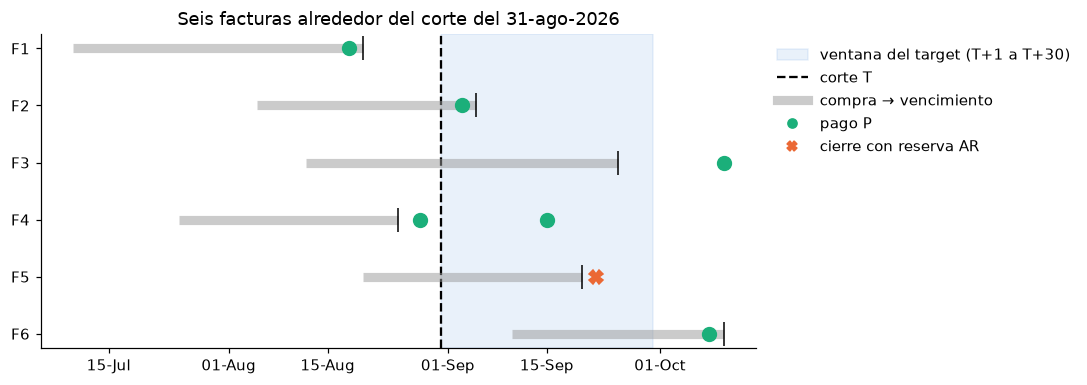

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(T, T + pd.Timedelta(days=H), color="#2a78d6", alpha=0.10, label="ventana del target (T+1 a T+30)")
ax.axvline(T, color="black", lw=1.5, ls="--", label="corte T")
estilo = {"P": dict(marker="o", color="#1baf7a"), "AR": dict(marker="X", color="#eb6834")}
for i, f in enumerate(facturas.itertuples()):
    ax.plot([f.compra, f.vence], [i, i], color="#999999", lw=6, solid_capstyle="butt", alpha=0.5)
    ax.plot(f.vence, i, marker="|", ms=16, color="black")
    for m in movs[movs["factura"] == f.factura].itertuples():
        ax.plot(m.fecha, i, ms=9, ls="none", **estilo[m.Tp])
ax.plot([], [], color="#999999", lw=6, alpha=0.5, label="compra → vencimiento")
ax.plot([], [], ls="none", label="pago P", **estilo["P"])
ax.plot([], [], ls="none", label="cierre con reserva AR", **estilo["AR"])
ax.set_yticks(range(len(facturas)), facturas["factura"]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title("Seis facturas alrededor del corte del 31-ago-2026")
plt.tight_layout(); plt.show()

Antes de ver la respuesta, **decidan para cada factura**: ¿entra al corte? ¿cuál es su target?

In [5]:
aplicado_hasta_T = movs[movs["fecha"] <= T].groupby("factura")["aplicado"].sum()
en_ventana = movs[(movs["fecha"] > T) & (movs["fecha"] <= T + pd.Timedelta(days=H)) & movs["Tp"].isin(["P", "PR"])]

foto = facturas.set_index("factura")
foto["comprada_en_T"] = foto["compra"] <= T
foto["saldo_en_T"] = foto["importe"] - aplicado_hasta_T.reindex(foto.index, fill_value=0)
foto["entra_al_corte"] = foto["comprada_en_T"] & (foto["saldo_en_T"] > 0)
foto["target_30d"] = en_ventana.groupby("factura")["net_cash"].sum().reindex(foto.index, fill_value=0)
foto.loc[~foto["entra_al_corte"], "target_30d"] = np.nan
display(foto[["importe", "comprada_en_T", "saldo_en_T", "entra_al_corte", "target_30d"]])

,importe,comprada_en_T,saldo_en_T,entra_al_corte,target_30d
factura,,,,,
F1,5000,True,0,False,NaN
F2,4000,True,4000,True,"4,000.00"
F3,6000,True,6000,True,0.00
F4,8000,True,3000,True,"3,000.00"
F5,3000,True,3000,True,0.00
F6,2000,False,2000,False,NaN


| Factura | ¿Qué pasó? | Lección |
|---|---|---|
| F1 | Se pagó el 18-ago, antes del corte | Ya no está abierta: **no entra** |
| F2 | Paga completo dentro de la ventana | Target = 4.000 |
| F3 | Paga el 10-oct, después de la ventana | **Entra con target 0.** No se borra: el cero también se aprende |
| F4 | Pagó 5.000 antes del corte y 3.000 dentro de la ventana | El saldo en `T` es 3.000, no 8.000. Target = 3.000 |
| F5 | Se cierra con reserva (`AR`) | Se cierra, pero no entra caja: target 0 |
| F6 | Se compró después del corte | **No entra**: no existía en `T` |

> F4 está vencida en el corte (venció el 25-ago) y aun así paga. F2 vence dentro de la ventana y paga. El vencimiento **orienta**, pero no decide.

## 4. La vista minable: de un corte a muchos cortes

Un solo corte da pocas filas para entrenar. La idea es **repetir la foto en cada cierre de mes** de la historia (el enunciado propone del 31-ene-2023 al 30-jun-2026 para entrenar) y apilar los resultados:

| factura | corte | días al vencimiento | saldo | mora histórica del pagador | … | **target 30 d** |
|---|---|---|---|---|---|---|
| F3 | 2026-08-31 | 25 | 6.000 | +12 | … | 0 |
| F3 | 2026-09-30 | −5 | 6.000 | +11 | … | 6.000 |
| F4 | 2026-08-31 | −6 | 3.000 | +4 | … | 3.000 |
| … | … | … | … | … | … | … |

Fíjense en que **F3 aparece dos veces**: estaba abierta en dos cortes. Eso tiene consecuencias en las secciones 5 y 6.

Construir esta tabla con los datos reales es el corazón del reto (y la parte que más pesa en la evaluación). Les toca resolver, entre otras cosas:

- **Llaves:** cómo unir facturas y movimientos. El número de factura podría repetirse entre clientes: comprueben empíricamente que la llave que elijan es única.
- **Saldo en cada corte:** a partir de los movimientos, incluidos créditos y cierres con reserva.
- **Variables históricas del pagador** (y, si sirve, del par cliente–pagador) calculadas solo con lo ocurrido antes del corte.
- **Fechas:** `Post Date` es la fecha de registro, no necesariamente la de disponibilidad de fondos. Puede haber movimientos con fecha retroactiva. Declárenlo como limitación.

Para las secciones siguientes usamos una vista minable **sintética** ya construida, que imita la estructura del problema de forma simplificada: cada factura se paga en un solo movimiento, o se cierra con reserva sin efectivo.

In [6]:
def synthetic_panel(seed=7, n_facturas=3000, n_pagadores=12):
    """Mundo sintético simplificado: un solo pago por factura (o cierre sin efectivo). No usa datos reales."""
    rng = np.random.default_rng(seed)
    pag = pd.DataFrame({
        "pagador": [f"PAG_{i:02d}" for i in range(n_pagadores)],
        "mora_base": rng.normal(3, 12, n_pagadores),            # días de retraso típicos del pagador
        "deriva": rng.choice([0, 0, 0, 12, -8], n_pagadores),    # cambio de comportamiento por año
        "pct_efectivo": rng.beta(8, 1.5, n_pagadores),           # probabilidad de pagar en efectivo
    })
    inicio = pd.Timestamp("2022-06-01")
    fac = pd.DataFrame({
        "factura": np.arange(1, n_facturas + 1),
        "pagador": rng.choice(pag["pagador"], n_facturas, p=rng.dirichlet(np.ones(n_pagadores) * 2)),
        "compra": inicio + pd.to_timedelta(rng.integers(0, 1550, n_facturas), unit="D"),
        "plazo": rng.choice([30, 45, 60, 90], n_facturas, p=[.35, .30, .25, .10]),
        "importe": np.round(np.exp(rng.normal(9, 1, n_facturas)), 2),
    }).merge(pag, on="pagador")
    fac["vence"] = fac["compra"] + pd.to_timedelta(fac["plazo"], unit="D")
    anios = (fac["vence"] - inicio).dt.days / 365
    mora = fac["mora_base"] + fac["deriva"] * anios - 0.15 * (fac["plazo"] - 45) + rng.normal(0, 8, n_facturas)
    fac["mora"] = np.maximum(mora.round(), 1 - fac["plazo"])     # nunca antes de la compra
    fac["cierre"] = fac["vence"] + pd.to_timedelta(fac["mora"], unit="D")
    fac["en_efectivo"] = rng.random(n_facturas) < fac["pct_efectivo"]

    filas = []
    for T in pd.date_range("2023-01-31", "2026-08-31", freq="ME"):
        abiertas = fac[(fac["compra"] <= T) & (fac["cierre"] > T)].copy()
        cerradas = fac[fac["cierre"] <= T]
        h = cerradas.groupby("pagador").agg(mora_hist=("mora", "mean"), efectivo_hist=("en_efectivo", "mean"))
        abiertas = abiertas.merge(h, on="pagador", how="left")
        abiertas["corte"] = T
        abiertas["dias_al_venc"] = (abiertas["vence"] - T).dt.days
        abiertas["saldo"] = abiertas["importe"]
        paga_en_ventana = abiertas["cierre"] <= T + pd.Timedelta(days=30)
        abiertas["target"] = np.where(paga_en_ventana & abiertas["en_efectivo"], abiertas["saldo"], 0.0)
        filas.append(abiertas)
    panel = pd.concat(filas, ignore_index=True)
    panel["mora_hist"] = panel["mora_hist"].fillna(panel["mora_hist"].mean())
    panel["efectivo_hist"] = panel["efectivo_hist"].fillna(panel["efectivo_hist"].mean())
    return panel.drop(columns=["mora_base", "deriva", "pct_efectivo", "cierre", "en_efectivo"]), fac

panel, fac = synthetic_panel()
print(f"Vista minable sintética: {len(panel):,} filas | {panel['corte'].nunique()} cortes | {panel['factura'].nunique():,} facturas distintas")
print(f"Filas por factura: media {panel.groupby('factura').size().mean():.1f} (una factura aparece en varios cortes)")
print(f"Filas con target = 0: {(panel['target'] == 0).mean():.0%}")
display(panel.sort_values(["factura", "corte"]).head(6)[["factura", "pagador", "corte", "dias_al_venc", "saldo", "mora_hist", "efectivo_hist", "target"]])

Vista minable sintética: 4,070 filas | 44 cortes | 2,354 facturas distintas
Filas por factura: media 1.7 (una factura aparece en varios cortes)
Filas con target = 0: 51%


,factura,pagador,corte,dias_al_venc,saldo,mora_hist,efectivo_hist,target
586,1,PAG_05,2023-07-31,43,"7,166.33",-9.05,0.87,0.00
707,1,PAG_05,2023-08-31,12,"7,166.33",-9.02,0.86,"7,166.33"
2371,2,PAG_10,2025-02-28,66,"4,598.07",-2.17,0.96,0.00
2444,2,PAG_10,2025-03-31,35,"4,598.07",-2.47,0.95,"4,598.07"
3609,4,PAG_05,2026-04-30,26,"7,474.85",-9.61,0.87,"7,474.85"
2857,5,PAG_00,2025-08-31,40,"4,098.77",22.41,0.93,0.00


> La función de arriba es un **simulador**, no la solución. Con los datos reales hay pagos parciales, reversos, créditos, cierres con reserva, movimientos `NF` y llaves que comprobar. Nada de eso está aquí.

## 5. Fuga de información: la variable que parece perfecta

La **fuga de información** (*data leakage*) ocurre cuando una variable usa datos que no se conocían en la fecha de corte. El modelo se ve excelente en la evaluación y falla en producción.

El caso típico en este reto: calcular la **mora promedio del pagador con toda la historia** en lugar de hacerlo solo con las facturas cerradas antes del corte. Si el pagador cambió su comportamiento, el promedio "completo" le está contando al modelo el futuro.

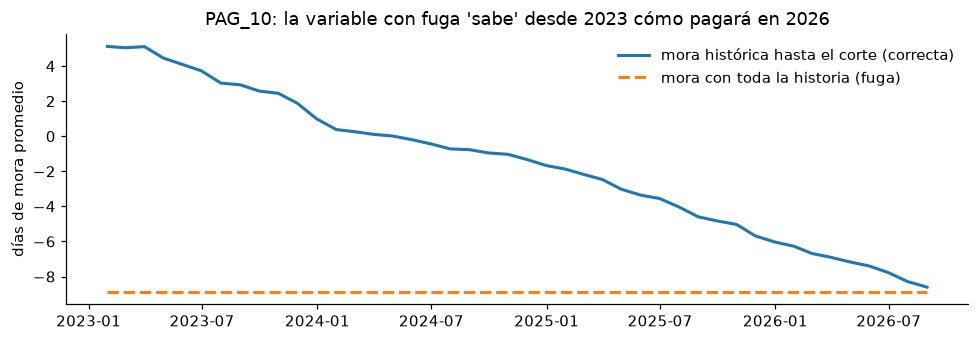

In [7]:
mora_completa = fac.groupby("pagador")["mora"].mean().rename("mora_completa")
panel = panel.merge(mora_completa, on="pagador")

cambio = fac.groupby("pagador")["mora"].agg(lambda s: s.iloc[-50:].mean() - s.iloc[:50].mean())
p_ej = cambio.abs().idxmax()     # el pagador cuyo comportamiento más cambió
serie = panel[panel["pagador"] == p_ej].groupby("corte")[["mora_hist", "mora_completa"]].first()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(serie.index, serie["mora_hist"], lw=2, label="mora histórica hasta el corte (correcta)")
ax.plot(serie.index, serie["mora_completa"], lw=2, ls="--", label="mora con toda la historia (fuga)")
ax.set_ylabel("días de mora promedio"); ax.legend(frameon=False)
ax.set_title(f"{p_ej}: la variable con fuga 'sabe' desde 2023 cómo pagará en 2026")
plt.tight_layout(); plt.show()

El gráfico muestra el problema de fondo. Ahora veamos su versión más común y más dañina: un equipo calcula la **tasa de recaudo del pagador en el mes** (qué fracción de sus facturas abiertas pagó) agrupando por pagador y corte... sin notar que esos pagos ocurren *dentro de la ventana del target*.

In [8]:
def mae(y, yhat):
    return np.mean(np.abs(np.asarray(y) - np.asarray(yhat)))

# Variable con fuga: usa los pagos de la ventana T+1..T+30, es decir, el propio target
panel["tasa_pagador_mes"] = panel.groupby(["pagador", "corte"])["target"].transform(lambda s: (s > 0).mean())

train = panel[panel["corte"] <= "2025-12-31"]
test = panel[panel["corte"] > "2025-12-31"]
resultado = {}
for nombre, extra in [("sin fuga", []), ("con fuga (+ tasa_pagador_mes)", ["tasa_pagador_mes"])]:
    X_cols = ["dias_al_venc", "mora_hist", "efectivo_hist", "plazo"] + extra
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    clf.fit(train[X_cols], train["target"] > 0)
    yhat = clf.predict_proba(test[X_cols])[:, 1] * test["saldo"]
    resultado[nombre] = mae(test["target"], yhat)
display(pd.Series(resultado, name="MAE por factura en 2026").to_frame())

,MAE por factura en 2026
sin fuga,"3,901.41"
con fuga (+ tasa_pagador_mes),"3,344.91"


Con la variable con fuga el error baja cerca de un 14 %, incluso evaluando por fecha. **Esa mejora es falsa**: el día que pronostiquen la cartera actual, los pagos del próximo mes todavía no existen y la variable no se puede calcular. La evaluación les promete algo que el modelo no va a cumplir.

**Regla práctica:** para cada variable pregúntense *"¿el analista podía calcular este número el día del corte?"*. Si una variable mejora el modelo "demasiado", sospechen de ella primero. Y las variables históricas del pagador se calculan solo con facturas **ya cerradas antes del corte**.

## 6. Validación por fecha, no aleatoria

En el curso usamos `train_test_split` y K-fold con partición aleatoria ([L6](L6_CrossValidation.ipynb)). Aquí eso **engaña**, por dos razones:

1.  **La misma factura aparece en varios cortes** con casi las mismas variables y un target parecido. Si una fila queda en train y su "gemela" en test, el modelo solo tiene que memorizarla.
2.  **El objetivo es predecir el futuro.** La evaluación tiene que imitar ese uso: entrenar con el pasado y medir con cortes posteriores.

Comparemos un árbol de decisión ([L9](L9_NaiveBayes_CART.ipynb)) evaluado de las dos formas.

In [9]:
X_cols = ["dias_al_venc", "mora_hist", "efectivo_hist", "plazo", "importe"]
arbol = lambda: DecisionTreeRegressor(min_samples_leaf=5, random_state=0)
frac = panel["target"] / panel["saldo"]

# (a) K-fold aleatorio por filas
errores = []
for tr, te in KFold(5, shuffle=True, random_state=0).split(panel):
    m = arbol().fit(panel.iloc[tr][X_cols], frac.iloc[tr])
    errores.append(mae(panel.iloc[te]["target"], m.predict(panel.iloc[te][X_cols]) * panel.iloc[te]["saldo"]))

# (b) Partición cronológica: entrenar hasta dic-2025 y medir en 2026
m = arbol().fit(train[X_cols], train["target"] / train["saldo"])
temporal = mae(test["target"], m.predict(test[X_cols]) * test["saldo"])

display(pd.Series({"K-fold aleatorio (optimista)": np.mean(errores), "Partición por fecha (realista)": temporal},
                  name="MAE por factura").to_frame())

,MAE por factura
K-fold aleatorio (optimista),"3,371.46"
Partición por fecha (realista),"4,238.45"


El K-fold aleatorio promete un error menor del que el modelo tendrá de verdad. Por eso el enunciado fija la evaluación **por fecha de corte**:

| Etapa | Cortes | Uso |
|---|---|---|
| Entrenamiento | Cierres de mes, 31-ene-2023 a 30-jun-2026 | Ajustar modelos |
| Validación | 31-jul-2026 | Elegir modelo e hiperparámetros |
| Prueba final | 31-ago-2026 | Reportar una sola vez. **No se usa para elegir** |
| Pronóstico | Fecha del Invoice Aging | La cartera actual, aún sin respuesta |

Si quieren ajustar hiperparámetros con validación cruzada, háganlo **por bloques de fechas** (por ejemplo, varios cortes de validación consecutivos), nunca mezclando filas al azar.

## 7. Modelos base y métricas

Antes de cualquier modelo sofisticado necesitan un **piso**: si el modelo no supera una regla simple, no aporta. Con lo visto en el curso tienen un menú suficiente:

| Modelo | Idea | Dónde lo vimos |
|---|---|---|
| **Base por vencimientos** | Se cobra el 100 % de lo que vence dentro de la ventana o ya venció; 0 % del resto | (el piso que pide el enunciado) |
| **Tabla de tasas** | Tasa histórica de recaudo por tramo de días al vencimiento (y por cliente o pagador) | `groupby` |
| **Ridge** | Regresión lineal regularizada sobre la fracción del saldo cobrada | [L4b](L4b_Regularization.ipynb) |
| **Dos partes** | Regresión logística para "¿llega efectivo?" × saldo (o × una regresión del monto si hay pagos parciales) | [L5](L5_LogisticRegression.ipynb) |
| **Árbol (CART)** | Árbol de regresión sobre la fracción cobrada | [L9](L9_NaiveBayes_CART.ipynb) |

Y dos métricas mínimas, **en dinero**:

- **MAE por factura:** promedio de |pronóstico − real| por factura. ¿Sirve para decisiones individuales?
- **Error absoluto del total:** |suma de pronósticos − suma real| en el corte. ¿Sirve para la caja de la empresa?

In [10]:
TRAIN_FIN, VAL, TEST = pd.Timestamp("2026-06-30"), pd.Timestamp("2026-07-31"), pd.Timestamp("2026-08-31")
tr, va, te = panel[panel["corte"] <= TRAIN_FIN], panel[panel["corte"] == VAL], panel[panel["corte"] == TEST]
X_cols = ["dias_al_venc", "mora_hist", "efectivo_hist", "plazo"]
TRAMOS = [-np.inf, -30, 0, 15, 30, 60, np.inf]

def base_vencimientos(tr, df):
    return np.where(df["dias_al_venc"] <= 30, df["saldo"], 0.0)

def tabla_tasas(tr, df):
    t = tr.assign(tramo=pd.cut(tr["dias_al_venc"], TRAMOS)).groupby("tramo", observed=True)[["target", "saldo"]].sum()
    tasa = t["target"] / t["saldo"]
    return pd.cut(df["dias_al_venc"], TRAMOS).map(tasa).astype(float).fillna(0).to_numpy() * df["saldo"].to_numpy()

def ridge(tr, df):
    m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(tr[X_cols], tr["target"] / tr["saldo"])
    return np.clip(m.predict(df[X_cols]), 0, 1) * df["saldo"]

def dos_partes(tr, df):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[X_cols], tr["target"] > 0)
    return m.predict_proba(df[X_cols])[:, 1] * df["saldo"]

def arbol_cart(tr, df):
    m = DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=0).fit(tr[X_cols], tr["target"] / tr["saldo"])
    return m.predict(df[X_cols]) * df["saldo"]

MODELOS = {"Base por vencimientos": base_vencimientos, "Tabla de tasas": tabla_tasas, "Ridge": ridge,
           "Dos partes (logística)": dos_partes, "Árbol CART": arbol_cart}

filas = []
for nombre, f in MODELOS.items():
    yv = f(tr, va)
    filas.append({"modelo": nombre, "MAE por factura (val)": mae(va["target"], yv),
                  "Error abs. del total (val)": abs(np.sum(yv) - va["target"].sum()),
                  "Total pronosticado (val)": np.sum(yv)})
tabla = pd.DataFrame(filas).set_index("modelo").sort_values("MAE por factura (val)")
print(f"Validación {VAL.date()}: {len(va)} facturas abiertas | recaudo real {va['target'].sum():,.0f}")
display(tabla.style.format("{:,.0f}"))

Validación 2026-07-31: 89 facturas abiertas | recaudo real 839,139


,MAE por factura (val),Error abs. del total (val),Total pronosticado (val)
modelo,,,
Árbol CART,"4,416","21,852","860,991"
Dos partes (logística),"4,515","46,860","792,279"
Base por vencimientos,"4,577","285,806","1,124,945"
Ridge,"5,593","24,820","814,318"
Tabla de tasas,"6,808","35,370","803,768"


In [11]:
elegido = tabla.index[0]
y_test = MODELOS[elegido](panel[panel["corte"] <= VAL], te)    # se reentrena con todo lo conocido al 31-jul
print(f"Modelo elegido en validación: {elegido}")
print(f"Prueba {TEST.date()}: MAE por factura {mae(te['target'], y_test):,.0f} | "
      f"total real {te['target'].sum():,.0f} | pronosticado {np.sum(y_test):,.0f} | "
      f"error abs. del total {abs(np.sum(y_test) - te['target'].sum()):,.0f}")

Modelo elegido en validación: Árbol CART
Prueba 2026-08-31: MAE por factura 4,862 | total real 637,023 | pronosticado 569,229 | error abs. del total 67,794


**Para leer los resultados:**

- La **base por vencimientos** suele sobreestimar: supone que todo lo que vence se paga a tiempo y en efectivo.
- Un modelo puede ganar en MAE por factura y perder en el total (o al revés). Reporten **las dos métricas** y expliquen cuál importa más para Operaciones.
- El modelo se elige con **validación**; la prueba se mira **una vez** al final. Si después de mirar la prueba cambian de modelo, la prueba deja de ser prueba.
- En los datos reales unas pocas facturas grandes concentran buena parte del saldo. Revisen dónde se equivoca su modelo, no solo el promedio.

> En este mundo sintético cada factura se paga completa o no se paga, así que la "dos partes" se reduce a probabilidad × saldo. Con los datos reales hay pagos parciales: piensen si les conviene modelar también el monto.

## 8. Checklist de entregables y preparación

**Al cierre de la hackatón** (según el enunciado):

- [ ] **Notebook reproducible**: integración, limpieza, vista minable, modelos y evaluación.
- [ ] **Vista minable documentada**: unidad de análisis, llaves, reglas del target y variables (con su justificación).
- [ ] **Modelo reproducible**: recibe una cartera en una fecha de corte y devuelve un monto por factura. Si solo funciona para una fecha, no es reproducible.
- [ ] **Tabla de pronósticos sobre el Invoice Aging**: factura, cliente, pagador, saldo al corte, monto esperado a 30 días y totales por cliente, pagador y cartera.
- [ ] **Comparación con el pronóstico base** y explicación de las métricas.
- [ ] **Pitch** para el equipo de Operaciones: desarrollo del modelo, resultados, limitaciones y recomendaciones.
- [ ] *(Opcional)* Ventana aproximada de recaudo: días 1–10, 11–20, 21–30 o sin recaudo.

**Antes de la hackatón** (obligatorio):

- [ ] Revisar las cuatro bases y el enunciado, y **traer preguntas para los representantes de la empresa**. Algunas ideas: ¿qué diferencia hay entre `Post Date` y `Date`? ¿Hay movimientos con fecha retroactiva? ¿Por qué algunos clientes cierran muchas facturas con reserva?
- [ ] **Estado del arte**: buscar artículos sobre predicción de pagos de facturas, *cash-flow forecasting* o *accounts receivable* en las bases de datos de la Universidad.

**Errores que más cuestan puntos:**

1.  Usar información posterior al corte en las variables (sección 5).
2.  Evaluar con particiones aleatorias (sección 6).
3.  Contar notas crédito, cierres con reserva o movimientos `NF` como efectivo (sección 2).
4.  Borrar las facturas que no pagaron en la ventana: su target es 0 y el modelo tiene que aprenderlo (sección 3).
5.  No comparar contra el pronóstico base por vencimientos (sección 7).

## Conclusión

El reto no es elegir el algoritmo más sofisticado. Es **plantear bien el problema**: definir el target con las reglas del negocio, construir una vista minable sin fuga de información y evaluar como si estuvieran en la fecha de corte. Con eso, los modelos que ya conocen (regresión regularizada, logística, árboles) son un punto de partida sólido.

**Material de apoyo de hackatones anteriores:** [L11: Time Series](L11_TimeSeries.ipynb) (variables con rezagos y split cronológico), [L12: Multi-horizonte](L12_TimeSeries_MultiHorizont.ipynb) y [L13: Isolation Forest](L13_iforest_heristics.ipynb) (empaquetar el pipeline para ejecutarlo sobre un nuevo periodo).